In [501]:
import matplotlib.pyplot as plt
import numpy as np
import scipy
import skimage
import PolSARInversion
import PyPreprocess

import importlib
importlib.reload(PolSARInversion)
importlib.reload(PyPreprocess)

import netCDF4

view_aspect = 0.1 #for plotting convenience

In [342]:
# -- 1. SLC DATASET

load_new = False
#fn_1 = "/mnt/d/slc_arcticarchi/ALOS-P1_1__A-ORBIT__ALPSRP174611590.h5"
#fn_2 = "/mnt/d/slc_arcticarchi/ALOS-P1_1__A-ORBIT__ALPSRP176361590.h5"

fn_1 = "/mnt/d/slc_arcticarchi/250929rDevon/ALOS-P1_1__A-ORBIT__ALPSRP174611510.h5"
fn_2 = "/mnt/d/slc_arcticarchi/250929rDevon/ALOS-P1_1__A-ORBIT__ALPSRP176361510.h5"
fn_cache = "ALOSPolarimetric_2509_dataset_cached_Devon.pickle"

if (load_new):
    dataset = PyPreprocess.Pair_Dataset_SNAPh5(fn_1, fn_2, step_azi=20, step_rng=10, rubbersheet=True)
    dataset.cache(fn_cache)
else:
    dataset = PyPreprocess.Pair_Dataset_SNAPh5.load_cache(fn_cache)



In [31]:
# -- 2. AUXILIARY DATASET (ice thickness)

#fn_it = "Envisat_IceThicknessGridded/ice_thickness_nh_ease2-250_cdr-v3p0_200904.nc"
#data_it = netCDF4.Dataset(fn_it, 'r')
#it_ll = (data_it.variables['lat'][:], data_it.variables['lon'][:])
#sit_interpolated = data_it.variables['sea_ice_thickness'][0]
#interpolate_empty = True

#fn_it = "neXtSIM_IceThicknessGridded_P1M-m_1758866043354.nc"
fn_it = "cmems_mod_arc_phy_my_nextsim_P1M-m_1759120757433.nc"
data_it = netCDF4.Dataset(fn_it, 'r')
it_ll = np.array(np.meshgrid(data_it.variables['latitude'], data_it.variables['longitude'], indexing='ij'))
#sit_interpolated = data_it.variables['sithick'][0]
print(f"imported {fn_it}")

it_mesh = np.array(np.meshgrid(np.arange(it_ll[0].shape[0]), np.arange(it_ll[0].shape[1]), indexing='ij'))
tmp = (scipy.interpolate.RegularGridInterpolator((it_ll[0].mean(axis=1), it_ll[1].mean(axis=0)), it_mesh[0]),
       scipy.interpolate.RegularGridInterpolator((it_ll[0].mean(axis=1), it_ll[1].mean(axis=0)), it_mesh[1]))
#s1 pixel -> s1 lat/lon -> it pixel
tmp = (tmp[0](np.stack((dataset.lat.ravel(), dataset.lon.ravel()),axis=1)).reshape(dataset.lat.shape),
       tmp[1](np.stack((dataset.lat.ravel(), dataset.lon.ravel()),axis=1)).reshape(dataset.lat.shape))
it_coordmap = tmp
print("finished generating coordinate map.")

# interpolation of parameter
def processAux(auxdata, interpolate_empty=False):
    if (interpolate_empty):
        print("interpolation of null values specified - interpolating values..")
        tmp2 = it_mesh[:,~np.isnan(auxdata)]; tmp2 = np.stack(tmp2.reshape((2, tmp2.size//2)),axis=-1)
        auxdata = scipy.interpolate.LinearNDInterpolator(tmp2, auxdata[~np.isnan(auxdata)].ravel())
        auxdata = auxdata(np.stack(it_mesh.reshape((2,it_mesh.size//2)),axis=-1)).reshape(it_ll[0].shape)
        auxdata[np.isnan(auxdata)] = 0
        print("completed value generation.")
    else:
        auxdata[np.isnan(auxdata)] = 0
    return scipy.ndimage.map_coordinates(auxdata, it_coordmap)

sit = processAux(data_it.variables['sithick'][0])
sic = processAux(data_it.variables['siconc'][0])
sivx = processAux(data_it.variables['vxsi'][0])
sivy = processAux(data_it.variables['vysi'][0])

imported cmems_mod_arc_phy_my_nextsim_P1M-m_1759120757433.nc
finished generating coordinate map.


In [ ]:
from mpl_toolkits.basemap import Basemap
bm = Basemap(projection='cyl', llcrnrlat=dataset.lat.min(), urcrnrlat=dataset.lat.max(), \
            llcrnrlon=dataset.lon.min(), urcrnrlon=dataset.lon.max(), resolution='i', area_thresh=1)
is_land = np.vectorize(bm.is_land)

xpt, ypt = bm(dataset.lon, dataset.lat)
landmask = is_land(xpt,ypt)

Text(0.5, 1.0, 'sea ice thickness (neXtSIM product)')

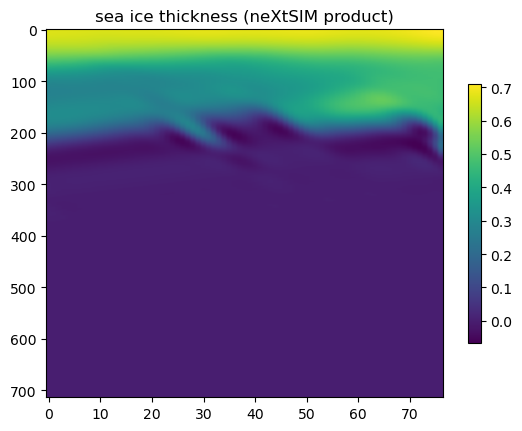

In [403]:
plt.imshow(sit[:,10:-10], aspect=view_aspect); plt.colorbar(shrink=0.7); plt.title('sea ice thickness (neXtSIM product)')
#plt.imshow(sic[:,10:-10], aspect=view_aspect); plt.colorbar(shrink=0.7); plt.title('sea ice concentration (neXtSIM product)')

In [268]:
# -- COMPARE HORIZONTAL ICE THICKNESS

#tmp = sit.copy(); tmp[landmask] = np.nan
#plt.plot(np.nanmean(tmp, axis=0)); plt.show()

#tmp = rvow.params[0].copy(); tmp[landmask]=np.nan
#plt.plot(np.nanmean(tmp[:,:-10], axis=0)); plt.show()

#tmp = sit.copy(); sit[landmask] = np.nan
#plt.hist(tmp.ravel(), bins=30)
#plt.title("interpolated sea ice thickness (m), ENVISAT Derived Product"); plt.show()

In [546]:
importlib.reload(PolSARInversion)

<module 'PolSARInversion' from '/mnt/c/Users/admin/Desktop/rnd/AISat/VolumeInversion/PolSARInversion.py'>

Beginning coherence function mapping...
(20, 20, 20)
coherence function initialized.
Beginning coherence function mapping...
(50, 30, 20)
coherence function initialized.
[          ]0.0% - 0/200
[          ]5.0% - 10/200
[#         ]10.0% - 20/200
[#         ]15.0% - 30/200
[##        ]20.0% - 40/200
[##        ]25.0% - 50/200
[###       ]30.0% - 60/200
[###       ]35.0% - 70/200
[####      ]40.0% - 80/200
[####      ]45.0% - 90/200
[#####     ]50.0% - 100/200
[#####     ]55.0% - 110/200
[######    ]60.0% - 120/200
[######    ]65.0% - 130/200
[#######   ]70.0% - 140/200
[#######   ]75.0% - 150/200
[########  ]80.0% - 160/200
[########  ]85.0% - 170/200
[######### ]90.0% - 180/200
[######### ]95.0% - 190/200


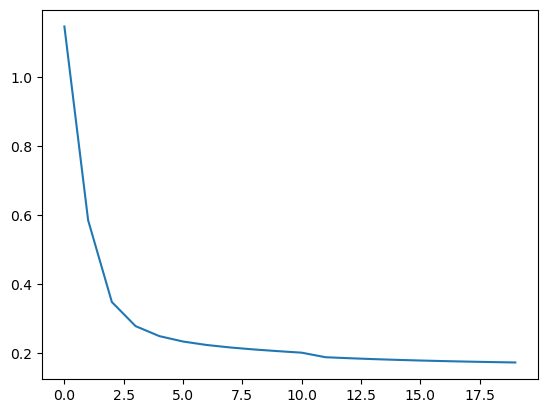

In [552]:
def extinction(z, h, t): return 15*(z/h)/(0.1*t) + 3.1#15*(z/h)/(0.1*np.log(t+1)) + 3.1
sigs = dataset.s1.copy(), dataset.s2.copy()
sigs = [np.array([el for el in img] + [img[0]-img[3], img[1]+img[2]]) for img in sigs] #just a few more bands :3
cohs = PolSARInversion.stackcoh(sigs[0], sigs[1], window_size=2)
rvow = PolSARInversion.RVoW(cohs, extinction, dataset.ia1, dataset.k_z, wavelength=0.236)
rvow.init_vol_coh(extinction, hgt_min=0.01, hgt_max=5, hgt_bins=50, age_min=5, age_max=200, age_bins=30, k_z_bins=20, smoothing=0.2)
#rvow.params[1] = 100 #ice age (days)

rvow.lr = 0.05
error_hist = rvow.converge(200, np.array([0.1, 1, 0.1, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05]))
plt.plot(error_hist)

In [462]:
#tmp = np.array([[0.1*i, 20, 48] for i in range(50)])
#plt.plot(tmp[:,0], np.angle(rvow.vol_coh(tmp)))
#plt.title("modelled volume coherence phase v. thickness using extinction algorithm @ age=20")

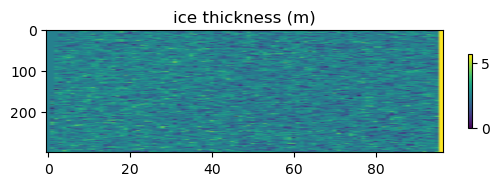

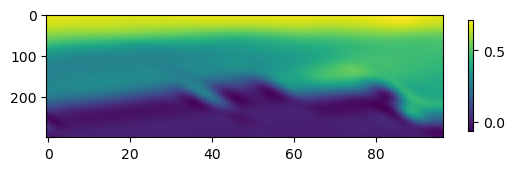

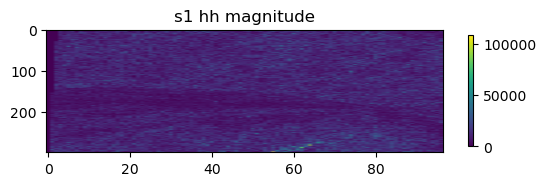

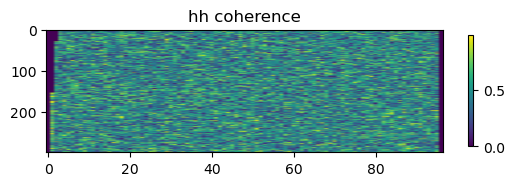

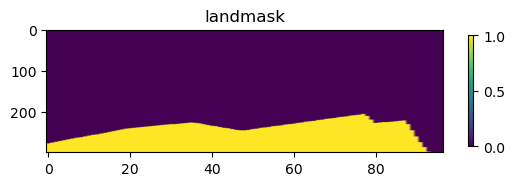

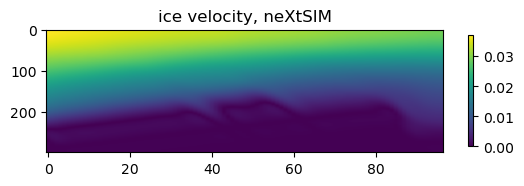

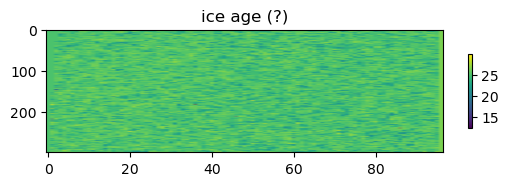

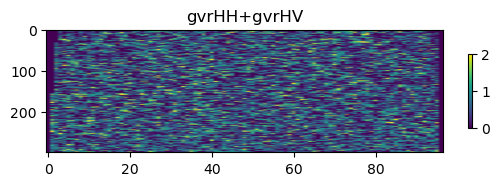

In [559]:
tmp = np.clip(rvow.params[0,:300,:], 0, 10).copy();# tmp[landmask[:,:]] = np.nan
plt.imshow(tmp, aspect=view_aspect); plt.colorbar(shrink=0.2); plt.title("ice thickness (m)"); plt.show()
#plt.hist(tmp.ravel(), bins=30); plt.title('ice thickness (m) histogram'); plt.show()

plt.imshow(sit[:300,:], aspect=view_aspect); plt.colorbar(shrink=0.3); plt.show()
plt.imshow(np.abs(dataset.s1[0,:300,:]), aspect=view_aspect); plt.colorbar(shrink=0.3); plt.title("s1 hh magnitude"); plt.show()
plt.imshow(np.abs(cohs[0,:300,:]), aspect=view_aspect); plt.colorbar(shrink=0.3); plt.title("hh coherence"); plt.show()
plt.imshow(landmask[:300,:], aspect=view_aspect); plt.title("landmask"); plt.colorbar(shrink=0.3); plt.show()
plt.imshow(((sivx**2 + sivy**2)**0.5)[:300,:], aspect=view_aspect); plt.title('ice velocity, neXtSIM'); plt.colorbar(shrink=0.3); plt.show();

tmp = rvow.params[1,:300,:].copy();# tmp[landmask[:,:]] = np.nan
plt.imshow(tmp, aspect=view_aspect); plt.colorbar(shrink=0.2); plt.title("ice age (?)"); plt.show()

#plt.imshow(np.sum(rvow.params[3:], axis=0), aspect=5); plt.colorbar(shrink=0.3); plt.show()

tmp = (rvow.params[3,:300]+rvow.params[4,:300])#+rvow.params[6])/(1+rvow.params[4]+rvow.params[5])
plt.imshow(tmp, aspect=view_aspect);
plt.colorbar(shrink=0.2); plt.title("gvrHH+gvrHV"); plt.show() #/ gvrHV+gvrVH

#plt.imshow(np.abs(cohs[0]),aspect=view_aspect);
#plt.title("coherence magnitude"); plt.show()

#plt.imshow(np.angle(cohs[0]),aspect=view_aspect);
#plt.title("coherence phase"); plt.show()

#plt.imshow(np.abs(dataset.ia1[:100,:100]), aspect=view_aspect); plt.show()
#tmp = dataset.k_z[:100,:100].copy(); tmp[tmp < 0.2] = np.max(tmp)
#plt.imshow(np.abs(tmp), cmap='gray', aspect=view_aspect); plt.show()

#plt.imshow(rvow.params[3], aspect=8); plt.colorbar(shrink=0.2); plt.show()
#plt.imshow(rvow.params[4], aspect=8); plt.colorbar(shrink=0.2); plt.show()
#plt.imshow(rvow.params[5], aspect=8); plt.colorbar(shrink=0.2); plt.show()
#plt.imshow(rvow.params[6], aspect=8); plt.colorbar(shrink=0.2); plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..42.21833339337348].


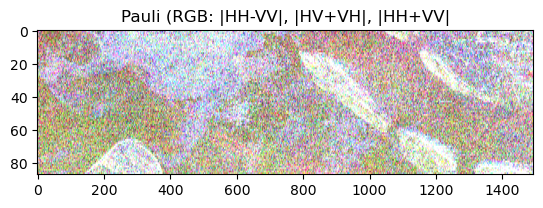

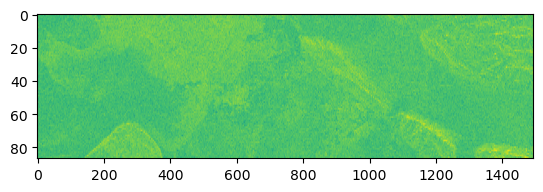

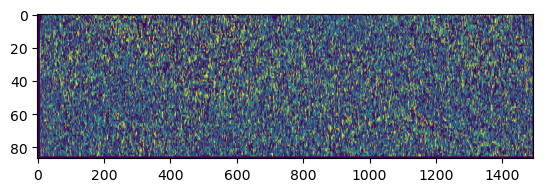

In [194]:
#plt.figure(figsize = (15,5))
rgb_hh_hv_vh = np.stack([(np.abs(s1o[0] - s1o[3])),
                         (np.abs(s1o[1] + s1o[2])),
                         (np.abs(s1o[1] + s1o[3]))], axis=-1)
a = np.mean(np.mean(rgb_hh_hv_vh, axis=0), axis=0)
rgb_hh_hv_vh /= a[np.newaxis, np.newaxis, :]
plt.imshow(rgb_hh_hv_vh, aspect=5);
plt.title("Pauli (RGB: |HH-VV|, |HV+VH|, |HH+VV|")
plt.show()

plt.imshow(np.log1p(np.abs(s1o[0])), aspect=5); plt.show()
plt.imshow((rvow.params[3]+rvow.params[6])/(1+rvow.params[4]+rvow.params[5]), aspect=5); plt.show()
#plt.imshow((rvow.params[4]), aspect=4); plt.show()
#plt.imshow((rvow.params[5]), aspect=4); plt.show()
#plt.imshow((rvow.params[6]), aspect=4); plt.show()

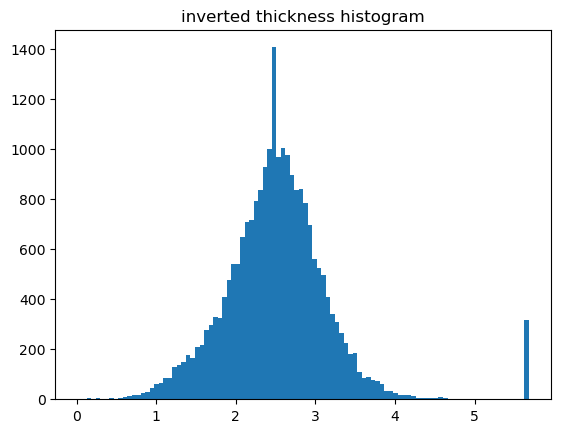

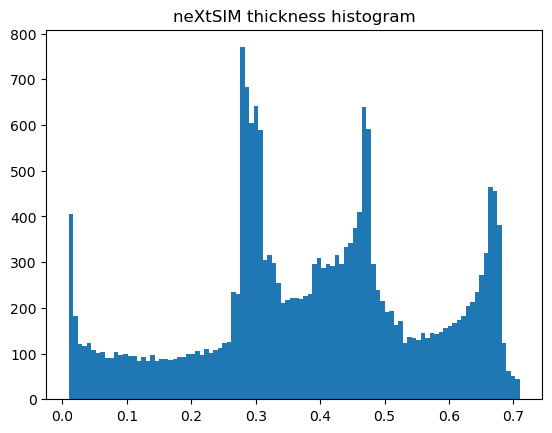

In [557]:
tmp = rvow.params[0].copy(); tmp[landmask]=np.nan; tmp = tmp.ravel()
plt.hist(tmp, bins=100); plt.title("inverted thickness histogram"); plt.show()
tmp = sit.ravel().copy(); tmp[tmp <= 0.01] = np.nan
plt.hist(tmp, bins=100); plt.title("neXtSIM thickness histogram"); plt.show()

[          ]0.0% - 0/500
[          ]2.0% - 10/500
[          ]4.0% - 20/500
[          ]6.0% - 30/500
[          ]8.0% - 40/500
[#         ]10.0% - 50/500
[#         ]12.0% - 60/500
[#         ]14.0% - 70/500
[#         ]16.0% - 80/500
[#         ]18.0% - 90/500
[##        ]20.0% - 100/500
[##        ]22.0% - 110/500
[##        ]24.0% - 120/500
[##        ]26.0% - 130/500
[##        ]28.0% - 140/500
[###       ]30.0% - 150/500
[###       ]32.0% - 160/500
[###       ]34.0% - 170/500
[###       ]36.0% - 180/500
[###       ]38.0% - 190/500
[####      ]40.0% - 200/500
[####      ]42.0% - 210/500
[####      ]44.0% - 220/500
[####      ]46.0% - 230/500
[####      ]48.0% - 240/500
[#####     ]50.0% - 250/500
[#####     ]52.0% - 260/500
[#####     ]54.0% - 270/500
[#####     ]56.0% - 280/500
[#####     ]58.0% - 290/500
[######    ]60.0% - 300/500
[######    ]62.0% - 310/500
[######    ]64.0% - 320/500
[######    ]66.0% - 330/500
[######    ]68.0% - 340/500
[#######   ]70.0% - 350/500
[#######

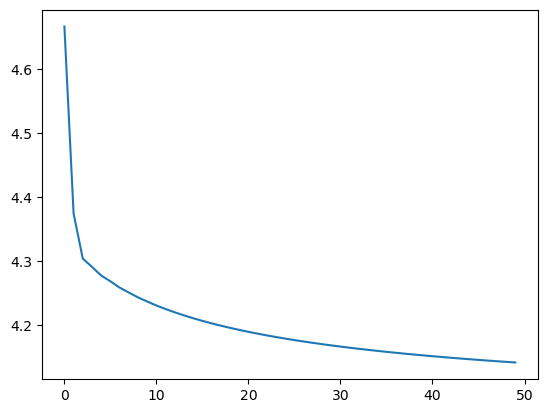

In [335]:
# -- VVHHr dielectric inverter -- #

vvhhr = np.abs(dataset.s1[3])/np.abs(dataset.s1[0]).copy()
vvhhr[np.isnan(vvhhr)] = 0
#print(vvhhr[np.newaxis, :].shape)
solver = PolSARInversion.IceVVHHr(vvhhr[np.newaxis, :].copy(), 21.5)
solver.params.shape

solver.lr = 0.01
error_hist = solver.converge(500, np.array([0.001, 0.01]))
plt.plot(error_hist); plt.show()

tmp = solver.params[0].copy(); tmp[landmask] = np.nan
plt.imshow(tmp, aspect = view_aspect); plt.colorbar(shrink=0.3); plt.title('rel. dielectric constant'); plt.show()
tmp = solver.params[1].copy(); tmp[landmask] = np.nan
plt.imshow(tmp, aspect = view_aspect); plt.colorbar(shrink=0.3); plt.title('angular standard deviation (roughness)'); plt.show()
plt.hist(solver.params[0].ravel(), bins=30); plt.title('rel. dielectric constant histogram'); plt.show()